# Analyze context identification models
The purpose of this notebook is to analyze the learned representations of models trained on the context identification task.

## Imports

In [1]:
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from adaptive_bottleneck.analysis import compute_scores_matrix

In [2]:
OUT_DIR = Path("../../data/context_identification_models")

## Visualize weight functions

In [3]:
def plot_attention_representations(
    params_attn,
    suptitle="Learned attention representations",
    save_path=None,
):
    """
    Plot W_q, W_k, pre-softmax attention scores, and W_v in a 2x2 panel.

    Panels:
        (0,0): W_q
        (0,1): W_k
        (1,0): Scores = Q K^T / sqrt(d)
        (1,1): W_v

    Args:
        params_attn (dict): Attention parameters with keys "W_q", "W_k", "W_v".
        suptitle (str): Figure suptitle.
        save_path (str or None): If provided, saves the figure to this path.
    """
    # --- Extract parameters ---
    Wq = np.array(params_attn["W_q"])  # (D_in, D_attn)
    Wk = np.array(params_attn["W_k"])  # (D_in, D_attn)
    Wv = np.array(params_attn["W_v"])  # (D_in, D_val)

    S0 = compute_scores_matrix(params_attn)

    # --- Plot ---
    fig, axes = plt.subplots(1, 2, figsize=(7, 3), constrained_layout=True)

    # Scores
    im = axes[0].imshow(S0, aspect="auto")
    axes[0].set_title("Scores")
    axes[0].set_xlabel("key index")
    axes[0].set_ylabel("query index")
    plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

    # W_v
    im = axes[1].imshow(Wv, aspect="auto")
    axes[1].set_title("W_v")
    axes[1].set_xlabel("value dim")
    axes[1].set_ylabel("input dim")
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

    fig.suptitle(suptitle, fontsize=12)

    if save_path is not None:
        plt.savefig(save_path, dpi=300)

    plt.show()


## Visualize weights for $\gamma=0$ on feature task

In [4]:
params_path = OUT_DIR / "context_id_feature_gamma0.0_softmax_seed0_params.pkl"
with open(params_path, "rb") as f:
    params_attn = pickle.load(f)

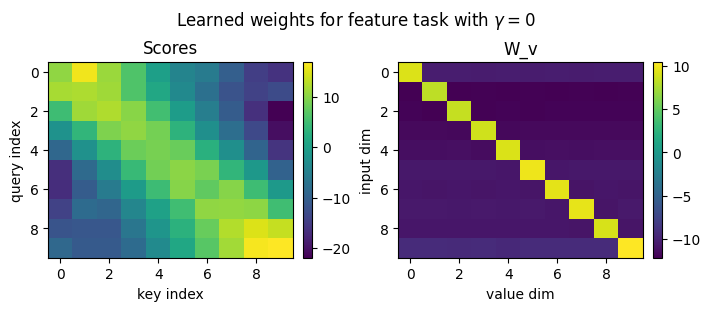

In [5]:
plot_attention_representations(
    params_attn, 
    r'Learned weights for feature task with $\gamma=0$',
    save_path='../../results/context_identification/fixed_gamma/learned_weights_feature_task_gamma0.png',
)

## Visualize weights for $\gamma=1$ on feature task

In [6]:
params_path = OUT_DIR / "context_id_feature_gamma1.0_softmax_seed0_params.pkl"
with open(params_path, "rb") as f:
    params_attn = pickle.load(f)

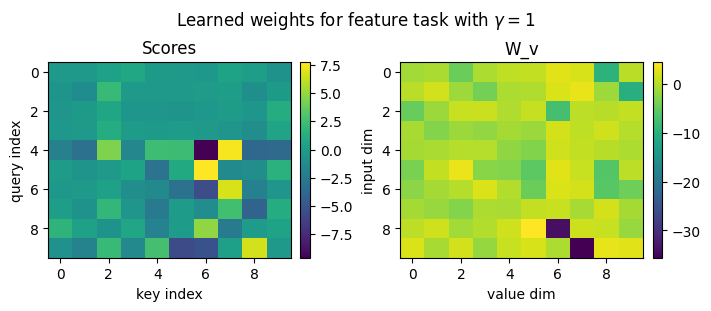

In [7]:
plot_attention_representations(
    params_attn, 
    r'Learned weights for feature task with $\gamma=1$',
    save_path='../../results/context_identification/fixed_gamma/learned_weights_feature_task_gamma1.png',
)

## Visualize weights for $\gamma=0$ on position task

In [8]:
params_path = OUT_DIR / "context_id_position_gamma0.0_softmax_seed0_params.pkl"
with open(params_path, "rb") as f:
    params_attn = pickle.load(f)

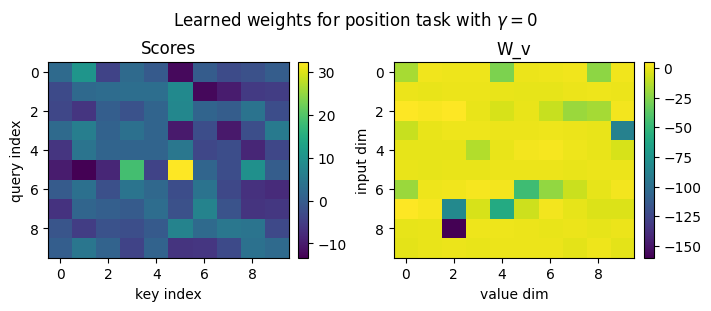

In [9]:
plot_attention_representations(
    params_attn, 
    r'Learned weights for position task with $\gamma=0$',
    save_path='../../results/context_identification/fixed_gamma/learned_weights_position_task_gamma0.png',
)

## Visualize weights for $\gamma=1$ on position task

In [10]:
params_path = OUT_DIR / "context_id_position_gamma1.0_softmax_seed3_params.pkl"
with open(params_path, "rb") as f:
    params_attn = pickle.load(f)

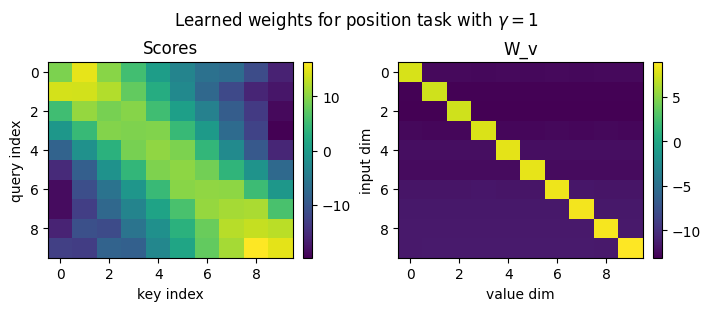

In [11]:
plot_attention_representations(
    params_attn, 
    r'Learned weights for position task with $\gamma=1$',
    save_path='../../results/context_identification/fixed_gamma/learned_weights_position_task_gamma1.png',
)